# Stage 0 — Original AToum Model: two-group CTC readout

This notebook now runs the original multi-area population-rate equations in `model_class.Model`, with the optional phase-gating extension in `ctc_model.CTCModel`. S is the V4 source area; W is the mean excitatory rate across F1, F2, F3, F4, 7a, and 7b. The model still contains all anatomical areas and FLN pathways.

Rates come from the original model's two excitatory populations, inhibitory population, synaptic variables, and FLN-derived currents. Phase oscillators are an explicit CTC extension; they are not part of the unmodified original equations.

A/B/C are wiring controls: A uses FLN phase coupling and gated inter-area excitation; B uses a shared phase drive with inter-area E→E transmission disabled; C uses directed V4→workspace phase drag. These are experiment conditions, not claims that the original model itself contains all three mechanisms.


## Step 1 — load the original model runner

The runner wraps `model_class.Model` and `ctc_model.CTCModel`. It retains the original network size, anatomical FLN matrix, rate equations, synapse states, and stimulus interface.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model_class.py').exists()), None)
if project_root is None:
    raise RuntimeError('Run Jupyter from the repository or a subdirectory.')
experiment_dir = project_root / 'project_experiment'
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(experiment_dir))
from stage0_two_node import DEFAULTS, simulate_stage0

print('Original model entry: model_class.Model')
print('CTC extension: ctc_model.CTCModel')


Original model entry: model_class.Model
CTC extension: ctc_model.CTCModel


## Step 2 — set the ignition candidate

The active `stage0_params` below use the active candidate: V4 receives 500 pA for 1000 ms, with CTC phase-gate depth 1.0 and K=10.8 rad/s. The original local and anatomical network parameters stay unchanged. A separate `original_baseline_params` dictionary is retained for the no-gate baseline and stimulus-only scans.


In [2]:
# Preserve a separate native-parameter baseline for comparisons and stimulus-only scans.
original_baseline_params = dict(DEFAULTS)
original_baseline_params.update({
    'sensory_area': 'V4',
    'workspace_areas': ['F1', 'F2', 'F3', 'F4', '7a', '7b'],
    'stimulus_drive': 0.90,  # 900 pA original-model baseline stimulus
    'g_sw': 0.95,  # neutral CTC adapter scale; gate depth 0 leaves original FLN unchanged
    'phase_gate_strength': 0.0,
})

# Step 2's active parameters are the successful candidate found by the search.
stage0_params = {
    **original_baseline_params,
    'stimulus_current_pA': 500.0,
    'stim_on_ms': 50.0,
    'stim_off_ms': 1050.0,
    'duration_ms': 1250.0,
    'g_sw': 0.95,
    'phase_coupling_rad_s': 10.8,
    'phase_gate_strength': 1.0,
}
candidate_params = dict(stage0_params)
candidate_seed = 12  # phase initialization that produced ignition in the grid search
print('Source:', stage0_params['sensory_area'])
print('Workspace:', ', '.join(stage0_params['workspace_areas']))
print(f"Candidate stimulus: {stage0_params['stimulus_current_pA']:g} pA for {stage0_params['stim_off_ms'] - stage0_params['stim_on_ms']:g} ms")
print(f"CTC phase gate: {stage0_params['phase_gate_strength']:g}; K: {stage0_params['phase_coupling_rad_s']:g} rad/s; candidate phase seed: {candidate_seed}")
print('Original local and anatomical connection parameters are unchanged.')


Source: V4
Workspace: F1, F2, F3, F4, 7a, 7b
Candidate stimulus: 500 pA for 1000 ms
CTC phase gate: 1; K: 10.8 rad/s; candidate phase seed: 12
Original local and anatomical connection parameters are unchanged.


## Step 3 — compare the original baseline with the ignition candidate

First run the original rate model with its phase gate off. Then compare the candidate found in the expanded search against same-seed controls: gate off, long-range E→E links disabled, and the one-way phase-drag configuration. The internal local and anatomical connection parameters remain unchanged throughout.


In [3]:
def stage0_record(label, condition, seed, params):
    result = simulate_stage0(condition, seed=seed, params=params)
    time = result['time_ms']
    stim_on = float(params.get('stim_on_ms', original_baseline_params['stim_on_ms']))
    stim_off = float(params.get('stim_off_ms', original_baseline_params['stim_off_ms']))
    during = (time >= stim_on) & (time < stim_off)
    return result, {
        'condition': label,
        'seed': seed,
        'stimulus_pA': params.get('stimulus_current_pA', float(params.get('stimulus_drive', 0.0)) * 1000),
        'duration_ms': stim_off - stim_on,
        'phase_gate_depth': params.get('phase_gate_strength', 0.0),
        'K_rad_s': params.get('phase_coupling_rad_s', 0.0),
        'ignited_20Hz_50ms': bool(result['ignited']),
        'latency_ms': result['ignition_latency_ms'],
        'peak_workspace_mean_hz': float(result['r_w_hz'].max()),
        'mean_workspace_during_stim_hz': float(result['r_w_hz'][during].mean()),
        'max_single_workspace_area_hz': float(result['workspace_area_rates_hz'].max()),
    }

baseline, baseline_row = stage0_record('Original baseline: A, gate off', 'A', 1, original_baseline_params)
_, baseline_no_link_row = stage0_record('Original baseline control: B, no E→E link', 'B', 1, original_baseline_params)
candidate, candidate_row = stage0_record('Candidate: A, gate on', 'A', candidate_seed, candidate_params)
_, gate_off_row = stage0_record('Candidate control: A, gate off', 'A', candidate_seed,
                                {**candidate_params, 'phase_gate_strength': 0.0})
_, no_link_row = stage0_record('Candidate control: B, no E→E link', 'B', candidate_seed, candidate_params)
_, one_way_row = stage0_record('Candidate control: C, one-way phase drag', 'C', candidate_seed, candidate_params)

stage0_comparison = pd.DataFrame([
    baseline_row, baseline_no_link_row, candidate_row,
    gate_off_row, no_link_row, one_way_row,
])
display(stage0_comparison)


,condition,seed,stimulus_pA,duration_ms,phase_gate_depth,K_rad_s,ignited_20Hz_50ms,latency_ms,peak_workspace_mean_hz,mean_workspace_during_stim_hz,max_single_workspace_area_hz
0,"Original baseline: A, gate off",1,900.0,450.0,0.0,2.5,False,NaN,14.795480,13.015175,37.178308
1,"Original baseline control: B, no E→E link",1,900.0,450.0,0.0,2.5,False,NaN,0.026049,0.024716,0.026467
2,"Candidate: A, gate on",12,500.0,1000.0,1.0,10.8,True,197.5,20.194589,18.262865,38.880095
3,"Candidate control: A, gate off",12,500.0,1000.0,0.0,10.8,False,NaN,14.672936,13.395302,36.658854
4,"Candidate control: B, no E→E link",12,500.0,1000.0,1.0,10.8,False,NaN,0.026049,0.024832,0.026467
5,"Candidate control: C, one-way phase drag",12,500.0,1000.0,1.0,10.8,False,NaN,19.266729,17.375264,39.145109


## Step 4 — inspect the candidate activity

The table above shows the original ungated baseline and the candidate/control results. Plot the candidate's workspace mean, phase relationship, and individual-area rates. A passing workspace mean still needs confirmation across more phase seeds before treating the setting as reliable.


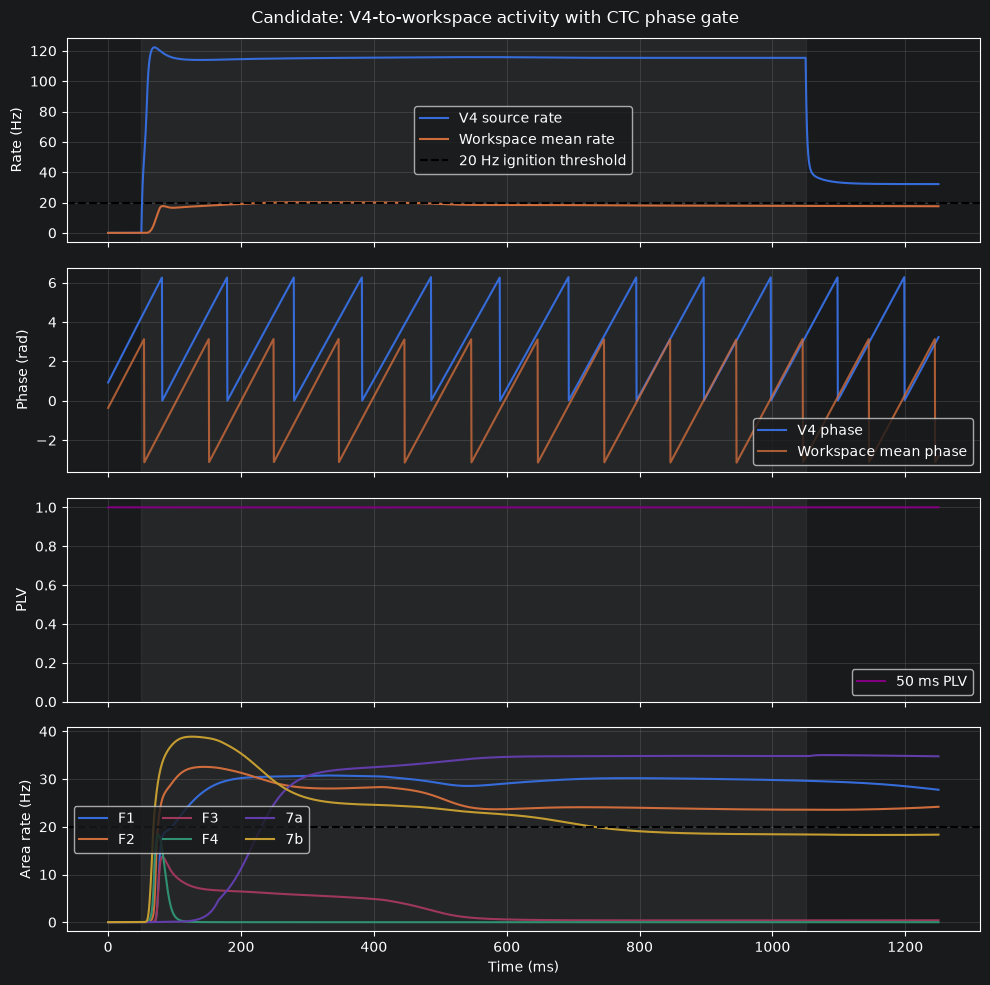

,area,peak_rate_hz,mean_rate_during_stim_hz
0,F1,30.750935,28.612351
1,F2,32.548830,25.615743
2,F3,13.705453,2.811044
3,F4,18.333155,0.365548
4,7a,35.022215,28.227092
5,7b,38.880095,23.945412


In [4]:
run = candidate
t_ms = run['time_ms']
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
axes[0].plot(t_ms, run['r_s_hz'], label='V4 source rate')
axes[0].plot(t_ms, run['r_w_hz'], label='Workspace mean rate')
axes[0].axhline(stage0_params['ignition_threshold_hz'], color='black', ls='--', label='20 Hz ignition threshold')
axes[0].set_ylabel('Rate (Hz)'); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot(t_ms, run['theta_s_rad'], label='V4 phase')
axes[1].plot(t_ms, run['theta_w_rad'], label='Workspace mean phase', alpha=.8)
axes[1].set_ylabel('Phase (rad)'); axes[1].legend(); axes[1].grid(alpha=.25)
axes[2].plot(t_ms, run['phase_locking_value'], color='purple', label='50 ms PLV')
axes[2].set_ylabel('PLV'); axes[2].set_ylim(0, 1.05); axes[2].legend(); axes[2].grid(alpha=.25)
for area_i, area_name in enumerate(stage0_params['workspace_areas']):
    axes[3].plot(t_ms, run['workspace_area_rates_hz'][:, area_i], label=area_name)
axes[3].axhline(stage0_params['ignition_threshold_hz'], color='black', ls='--')
axes[3].set_ylabel('Area rate (Hz)'); axes[3].set_xlabel('Time (ms)')
axes[3].legend(ncol=3); axes[3].grid(alpha=.25)
for ax in axes:
    ax.axvspan(candidate_params['stim_on_ms'], candidate_params['stim_off_ms'], color='gray', alpha=.12)
plt.suptitle('Candidate: V4-to-workspace activity with CTC phase gate')
plt.tight_layout(); plt.show()

stimulus_mask = (t_ms >= candidate_params['stim_on_ms']) & (t_ms < candidate_params['stim_off_ms'])
workspace_rate_summary = pd.DataFrame({
    'area': stage0_params['workspace_areas'],
    'peak_rate_hz': run['workspace_area_rates_hz'].max(axis=0),
    'mean_rate_during_stim_hz': run['workspace_area_rates_hz'][stimulus_mask].mean(axis=0),
})
display(workspace_rate_summary)


## Step 5 — current candidate and limitations

The active Stage 0 candidate is 500 pA for 1000 ms, CTC gate depth 1.0, K=10.8 rad/s, and `g_sw=0.95` (native long-range scale). Its current ignition check now covers 24 phase seeds: **2/24 trials (8.3%)** ignited, at latencies 197.5 ms (seed 12) and 299 ms (seed 23). The Wilson 95% interval is about 2.3%–25.8%. The candidate can produce ignition, but it is not a reliable ignition regime.

Small pilot sweeps over stimulus strength (400–800 pA), stimulus duration (500–1500 ms), K (4–14 rad/s), and gate depth (0–1) did not identify a setting with more than 1/3 ignition across seeds 1, 6, and 12. A separate 12-seed-per-setting scan of the existing `g_sw` scale also found ignition in only 1/12 trials at gains 1.0–1.5×, always for seed 12. Original local and anatomical parameters were retained; no new local recurrent gain was added. The CTC phase gate remains an explicit extension.

The combined 24-seed data are in `stage0_candidate_seed_check_500pa_24seeds.csv` and its summary in `stage0_candidate_summary_500pa_24seeds.csv`. The fresh-seed extension (seeds 13–24) is also available in `stage0_candidate_seed_check_500pa_fresh_seeds13_24.csv`. Treat this as exploratory evidence, not robust CTC ignition.


## Step 6 — expanded check of long-range FLN rate coupling

The original model computes long-range E→E currents from its FLN-weighted rate matrix (`model_class.Model`); the CTC adapter multiplies this input by `g_sw / 0.95`. We expanded the paired seed set to seeds 1–12. With the stimulus (500 pA, 1000 ms), K (10.8 rad/s), and ignition definition fixed, we scanned 0–3× native FLN gain with phase gate depth 1.0; a matched subset also used gate depth 0. The underlying anatomical FLN matrix was not edited. The combined scan contains 192 trials.

With the phase gate off, mean workspace rate rises from 0.025 Hz at 0× to 13.4 Hz at native 1× and 17.0 Hz at 2.85×, but ignition was 0/12 at every tested gain. With the gate on, workspace mean rate rises from 0.025 Hz at 0× to about 16.4 Hz at native gain and plateaus near 17 Hz at higher gains. Ignition was 1/12 at 1.0×, 1.15×, 1.3×, and 1.5×; it was 0/12 below 1.0× and above 1.5×. At higher gains some trial peak means exceeded 20 Hz, but did not remain above threshold for 50 ms. The highest observed single-area rate was about 51 Hz.

**Conclusion:** FLN rate coupling clearly transmits activity; CTC gating can increase its impact around native gain. Neither rate coupling alone nor stronger coupling produced repeatable sustained ignition in this scan. The 12-seed estimates are still exploratory; the 95% Wilson intervals for 1/12 are wide (about 1.5%–35.4%).

Expanded trial-level data, summary, and figure: `stage0_fln_gain_expanded_trials.csv`, `stage0_fln_gain_expanded_summary.csv`, and `stage0_fln_gain_expanded.png`.


,gate_depth,relative_FLN_gain,g_sw,n,ignited,ignition_probability,wilson95_low,wilson95_high,mean_latency_ms,mean_workspace_during_stim_hz,sem_workspace_during_stim_hz,mean_peak_workspace_mean_hz,mean_peak_single_area_hz,max_single_area_rate_hz
0,0.0,0.000,0.000,12,0,0.000,0.000,0.243,NaN,0.025,0.000,0.026,0.026,0.026
1,0.0,1.000,0.950,12,0,0.000,0.000,0.243,NaN,13.395,0.000,14.673,36.659,36.659
2,0.0,1.300,1.235,12,0,0.000,0.000,0.243,NaN,13.418,0.000,18.664,34.623,34.623
3,0.0,2.000,1.900,12,0,0.000,0.000,0.243,NaN,16.952,0.000,21.015,33.525,33.525
4,0.0,2.850,2.708,12,0,0.000,0.000,0.243,NaN,16.974,0.000,21.724,33.464,33.464
5,1.0,0.000,0.000,12,0,0.000,0.000,0.243,NaN,0.025,0.000,0.026,0.026,0.026
6,1.0,0.500,0.475,12,0,0.000,0.000,0.243,NaN,8.607,0.757,14.387,40.418,50.622
7,1.0,0.750,0.712,12,0,0.000,0.000,0.243,NaN,12.746,0.906,16.789,39.091,46.701
8,1.0,1.000,0.950,12,1,0.083,0.015,0.354,197.5,16.390,0.304,19.037,39.529,49.111
9,1.0,1.150,1.092,12,1,0.083,0.015,0.354,180.0,16.822,0.243,19.336,37.724,48.307


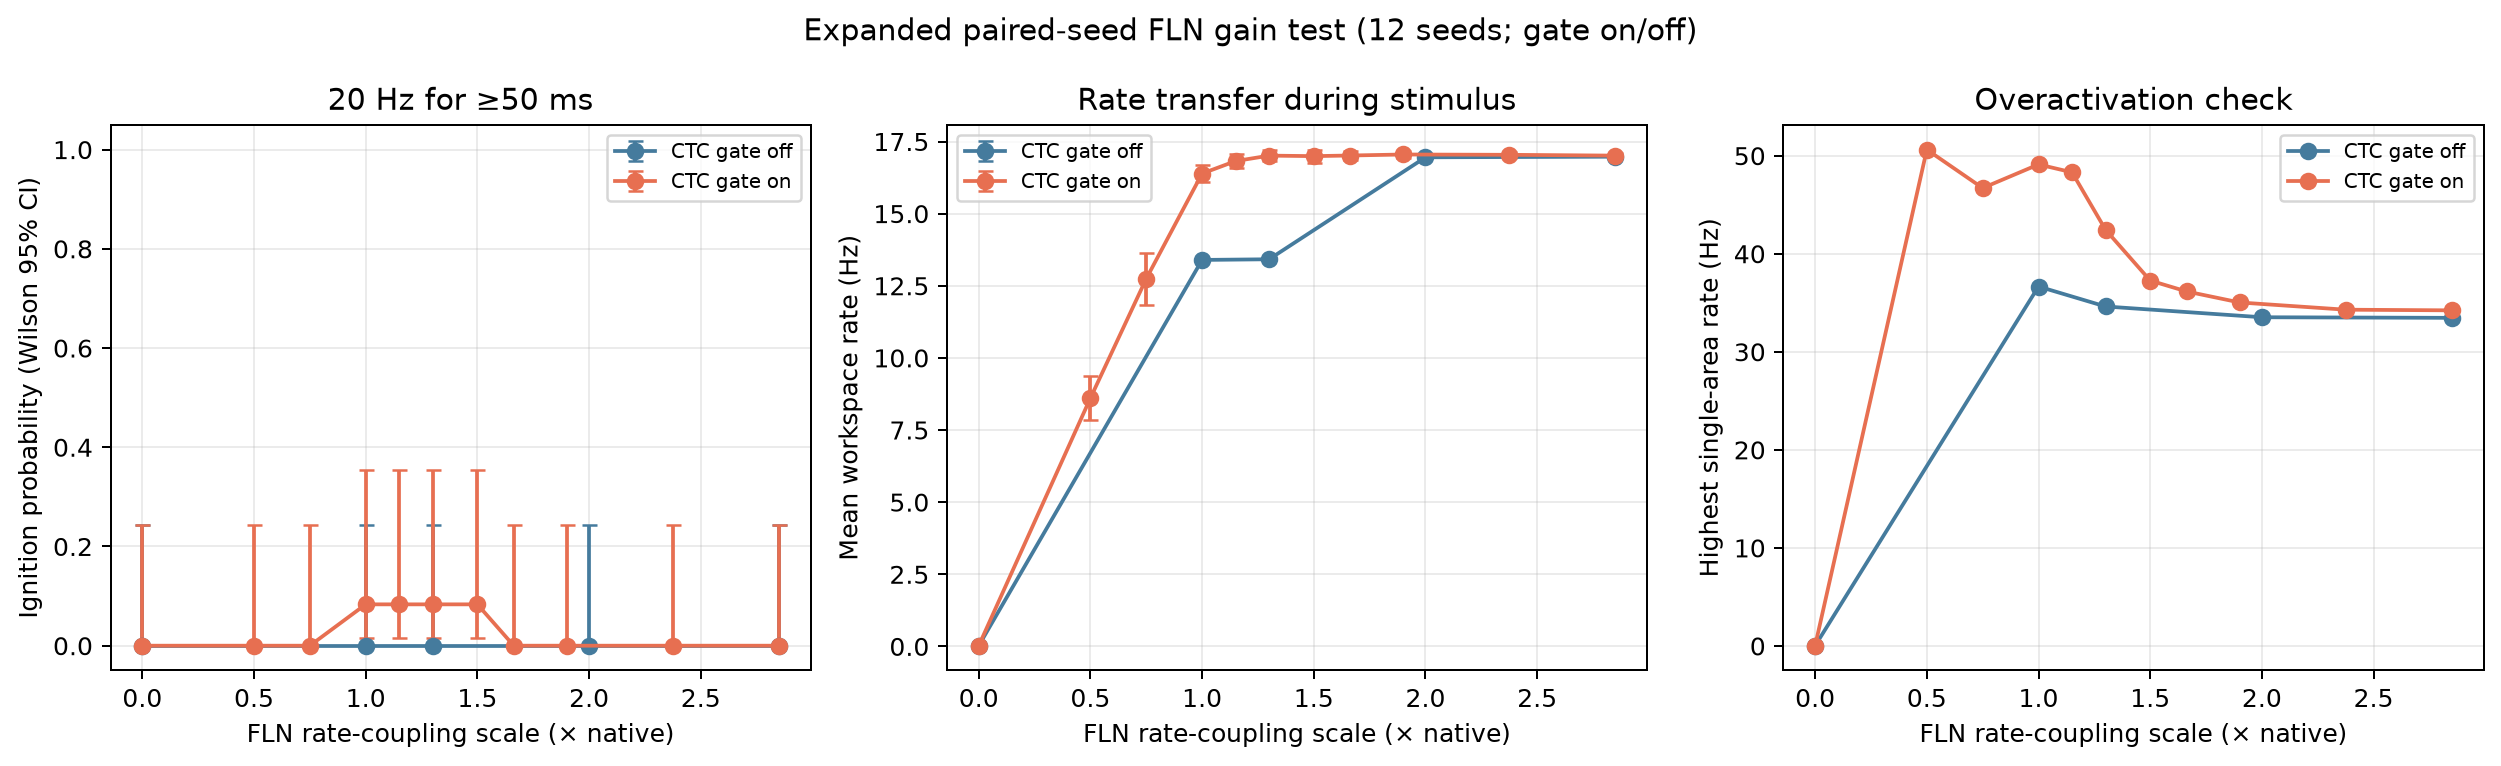

In [5]:
from IPython.display import Image
fln_gain_summary = pd.read_csv(project_root / 'project_experiment' / 'stage0_fln_gain_expanded_summary.csv')
display(fln_gain_summary.round(3))
display(Image(filename=str(project_root / 'project_experiment' / 'stage0_fln_gain_expanded.png')))

## Step 7 — validate workspace activity maintenance

The paired 24-seed Stage 0 follow-up compares the existing candidate with workspace re-entry off (0 pA) and on (50 pA). All other tested settings are held fixed: V4 stimulus 500 pA from 50 to 1050 ms, run to 1600 ms, native FLN scale 0.95, K=10.8 rad/s, and phase-gate depth 1.0.

`workspace_reentry_current_pA` is an optional extension: workspace mean rate feeds a smooth threshold function, which adds current to excitatory populations in workspace regions. At 0 pA it is disabled. This tests a candidate maintenance mechanism; it does not show that the unmodified AToum/FLN model or CTC alone maintains activity. The trial-level data and paired test are saved in the CSV files below.


,workspace_reentry_current_pA,n,ignited,ignition_probability,ignition_wilson95_low,ignition_wilson95_high,poststim_ignited,poststim_ignition_probability,poststim_wilson95_low,poststim_wilson95_high,median_latency_ms,mean_workspace_poststim_hz,max_poststim_duration_above20_ms,max_single_area_rate_hz
0,0.0,24,2,0.083,0.023,0.258,0,0.0,0.000,0.138,248.25,16.941,0.0,49.111
1,50.0,24,24,1.000,0.862,1.000,24,1.0,0.862,1.000,197.00,26.628,550.5,52.450


,comparison,n_seeds,feedback_only_ignition,off_only_ignition,paired_ignition_difference,mcnemar_exact_two_sided_p,mcnemar_exact_one_sided_p,feedback_only_poststim_ignition,off_only_poststim_ignition,paired_poststim_ignition_difference,poststim_mcnemar_two_sided_p
0,50pA feedback minus off,24,22,0,0.916667,4.768372e-07,2.384186e-07,24,0,1.0,1.192093e-07


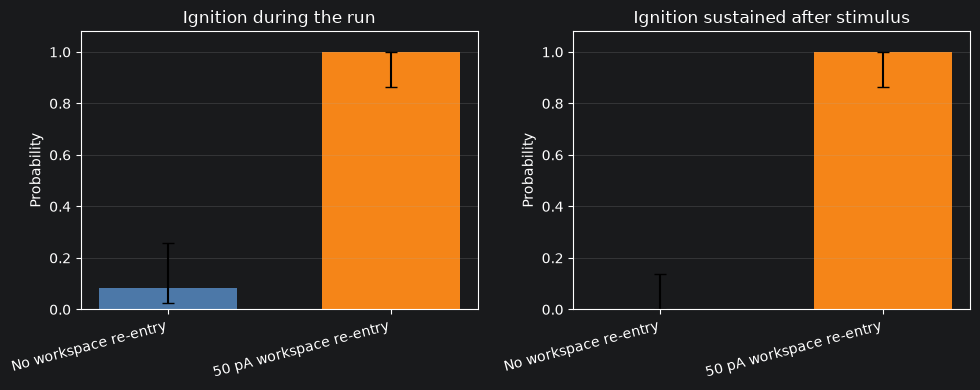

In [6]:
reentry_dir = project_root / 'project_experiment'
reentry_summary = pd.read_csv(reentry_dir / 'stage0_workspace_reentry_confirm_summary.csv')
reentry_contrast = pd.read_csv(reentry_dir / 'stage0_workspace_reentry_confirm_contrast.csv')
reentry_trials = pd.read_csv(reentry_dir / 'stage0_workspace_reentry_confirm_trials.csv')
assert (reentry_trials.groupby('workspace_reentry_current_pA')['seed'].nunique() == 24).all()
display(reentry_summary.round(3))
display(reentry_contrast)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ['No workspace re-entry', '50 pA workspace re-entry']
colors = ['#4C78A8', '#F58518']
x = np.arange(len(reentry_summary))
for ax, rate_col, low_col, high_col, title in [
    (axes[0], 'ignition_probability', 'ignition_wilson95_low', 'ignition_wilson95_high', 'Ignition during the run'),
    (axes[1], 'poststim_ignition_probability', 'poststim_wilson95_low', 'poststim_wilson95_high', 'Ignition sustained after stimulus'),
]:
    y = reentry_summary[rate_col].to_numpy()
    yerr = np.vstack([y - reentry_summary[low_col].to_numpy(), reentry_summary[high_col].to_numpy() - y])
    ax.bar(x, y, color=colors, width=0.62)
    ax.errorbar(x, y, yerr=yerr, fmt='none', ecolor='black', capsize=4)
    ax.set_xticks(x, labels, rotation=15, ha='right')
    ax.set_ylim(0, 1.08); ax.set_ylabel('Probability'); ax.set_title(title); ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.savefig(reentry_dir / 'stage0_workspace_reentry_confirm.png', dpi=160, bbox_inches='tight')
plt.show()


### Stage 0 interpretation

In the current 24-seed paired confirmation, ignition increased from 2/24 at 0 pA to 24/24 at 50 pA; post-stimulus sustained ignition increased from 0/24 to 24/24 over the 550 ms observation window. The highest single-area rate changed from about 49 to 52 Hz. This is a strong result for the tested settings, but it is conditional on the explicit positive-feedback extension and should be replicated at additional seeds/current values before treating 50 pA as a robust operating point.